# Projekt Z6 · Wpływ przygotowania danych na FFNN i SOM

## Cel i dane

Jak skalowanie i sposób obsługi braków wpływają na wyniki FFNN i SOM? W Adult przewidujemy, czy roczny dochód przekracza 50 tys. USD (klasa 1). W Banknote rozróżniamy klasy 0 i 1 na podstawie cech obrazów banknotów. Przed podziałem danych usuwamy pełne duplikaty. W Adult zapis „?” oznacza brak.

W Colabie uruchom wszystkie komórki w kolejności. Notebook użyje lokalnych plików UCI lub pobierze dane przez ucimlrepo.

[Adult w repozytorium UCI](https://archive.ics.uci.edu/dataset/2/adult) · [Banknote w repozytorium UCI](https://archive.ics.uci.edu/dataset/267/banknote+authentication)

In [1]:
%pip install -q "minisom==2.3.5" "ucimlrepo==0.0.7" "tensorflow>=2.16,<3" "scikit-learn>=1.2" "seaborn>=0.12"

Note: you may need to restart the kernel to use updated packages.


In [2]:
from importlib.metadata import version
from pathlib import Path
import platform

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import Markdown, display
from minisom import MiniSom
from scipy.spatial.distance import cdist
from sklearn.compose import ColumnTransformer
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from tensorflow import keras
from ucimlrepo import fetch_ucirepo

SEED = 42
HOLDOUT_SHARE = 0.30
TEST_SHARE_OF_HOLDOUT = 0.50

FFNN = dict(
    hidden_units=(32, 16), hidden_activation='relu', output_activation='sigmoid',
    optimizer=keras.optimizers.Adam, loss='binary_crossentropy', learning_rate=0.001,
    max_epochs=100, batch_size=64, monitor='val_loss', patience=10, threshold=0.5,
)

SOM = dict(
    neurons_factor=5, sigma_min=1, sigma_divisor=4, learning_rate=0.5,
    updates=10_000, distance_batch_size=1024,
    topology='rectangular', activation_distance='euclidean',
    neighborhood_function='gaussian', decay_function='asymptotic_decay',
    sigma_decay_function='asymptotic_decay',
)

SCALERS = {'StandardScaler': StandardScaler, 'MinMaxScaler': MinMaxScaler}
ADULT_VARIANTS = {
    'A1': ('A', 'StandardScaler'), 'A2': ('A', 'MinMaxScaler'),
    'B1': ('B', 'StandardScaler'), 'B2': ('B', 'MinMaxScaler'),
    'C1': ('C', 'StandardScaler'), 'C2': ('C', 'MinMaxScaler'),
}
BANK_VARIANTS = {'N1': ('N', 'StandardScaler'), 'N2': ('N', 'MinMaxScaler')}
ADULT_VARIANTS['A1-L1'] = ADULT_VARIANTS['A1']
ADULT_VARIANTS['A1-64x32'] = ADULT_VARIANTS['A1']
ADULT_VARIANTS['A1-Leaky'] = ADULT_VARIANTS['A1']
BANK_VARIANTS['N1-L1'] = BANK_VARIANTS['N1']
SOM_ONLY_VARIANTS = {'A1-L1': 'manhattan', 'N1-L1': 'manhattan'}
FFNN_ONLY_VARIANTS = {
    'A1-64x32': dict(hidden_units=(64, 32)),
    'A1-Leaky': dict(negative_slope=0.01),
}
CDIST_METRICS = {'euclidean': 'euclidean', 'manhattan': 'cityblock'}
MISSING_CATEGORY = 'BRAK_DANYCH'

sns.set_theme(style='whitegrid')
libraries = (
    'pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy', 'scikit-learn',
    'tensorflow', 'keras', 'minisom', 'ucimlrepo',
)
versions = [f'Python {platform.python_version()}']
versions.extend(f'{name} {version(name)}' for name in libraries)
print(' · '.join(versions))

Python 3.13.7 · pandas 2.3.3 · numpy 2.2.5 · matplotlib 3.10.7 · seaborn 0.13.2 · scipy 1.16.2 · scikit-learn 1.9.1 · tensorflow 2.21.0 · keras 3.15.1 · minisom 2.3.5 · ucimlrepo 0.0.7


In [3]:
ADULT_COLUMNS = (
    'age workclass fnlwgt education education-num marital-status occupation '
    'relationship race sex capital-gain capital-loss hours-per-week native-country'
).split()
ADULT_NUMERIC = 'age fnlwgt education-num capital-gain capital-loss hours-per-week'.split()
BANK_NUMERIC = ['variance', 'skewness', 'curtosis', 'entropy']


def load_adult():
    files = [Path('adult.data'), Path('adult.test')]
    if all(path.is_file() for path in files):
        options = dict(names=[*ADULT_COLUMNS, 'class'], skipinitialspace=True, comment='|')
        raw = pd.concat([pd.read_csv(path, **options) for path in files], ignore_index=True)
        x, target = raw[ADULT_COLUMNS].copy(), raw['class']
        source = 'lokalne pliki UCI'
    else:
        data = fetch_ucirepo(id=2).data
        x, target = data.features.copy(), data.targets.iloc[:, 0]
        x = x[ADULT_COLUMNS]
        source = 'ucimlrepo (UCI 2)'

    for name in x.columns.difference(ADULT_NUMERIC):
        column = x[name].astype(object)
        x[name] = column.str.strip().replace('?', np.nan).astype(object)
        x[name] = x[name].where(x[name].notna(), np.nan)
    x[ADULT_NUMERIC] = x[ADULT_NUMERIC].replace(r'^\s*\?\s*$', np.nan, regex=True)
    x[ADULT_NUMERIC] = x[ADULT_NUMERIC].apply(pd.to_numeric)
    y = target.str.strip().str.rstrip('.').map({'<=50K': 0, '>50K': 1})
    return x, y, source


def load_banknote():
    path = Path('data_banknote_authentication.txt')
    if path.is_file():
        raw = pd.read_csv(path, names=[*BANK_NUMERIC, 'class'])
        return raw[BANK_NUMERIC], raw['class'], 'lokalny plik UCI'
    data = fetch_ucirepo(id=267).data
    return data.features[BANK_NUMERIC], data.targets.iloc[:, 0], 'ucimlrepo (UCI 267)'


def inspect_and_split(x, y, source):
    if not y.isin([0, 1]).all():
        raise ValueError('Oczekiwano etykiet 0 i 1 dla wszystkich rekordów.')
    y = y.astype('int64').rename('class')
    raw = x.assign(class_=y).rename(columns={'class_': 'class'})
    clean = raw.drop_duplicates()
    x, y = clean.drop(columns='class'), clean['class']
    missing = int(x.isna().any(axis=1).sum())
    summary = {
        'Źródło': source,
        'Rekordy źródłowe': len(raw),
        'Duplikaty': len(raw) - len(clean),
        'Rekordy z brakami po czyszczeniu': missing,
        'Z brakami (%)': round(100 * missing / len(clean), 2),
        'Klasa 0 po czyszczeniu': int(y.eq(0).sum()),
        'Klasa 1 po czyszczeniu': int(y.eq(1).sum()),
    }

    x_train, x_holdout = train_test_split(
        x, test_size=HOLDOUT_SHARE, stratify=y, random_state=SEED,
    )
    x_val, x_test = train_test_split(
        x_holdout, test_size=TEST_SHARE_OF_HOLDOUT, stratify=y.loc[x_holdout.index],
        random_state=SEED,
    )
    return summary, y, (x_train, x_val, x_test), clean


adult_summary, adult_y, adult_splits, adult_data = inspect_and_split(*load_adult())
bank_summary, bank_y, bank_splits, bank_data = inspect_and_split(*load_banknote())

### Przykładowe rekordy

Pokazujemy po pięć wierszy po usunięciu duplikatów. W Adult klasa 0 oznacza dochód do 50 tys. USD, a klasa 1 dochód powyżej tej kwoty. W Banknote używamy kodów 0 i 1.

In [4]:
for name, frame in [('Adult', adult_data), ('Banknote', bank_data)]:
    display(Markdown(f'**{name}**'))
    display(frame.head().rename(columns={'class': 'Klasa'}).replace({np.nan: 'Brak danych'}))

display(Markdown('**Podsumowanie zbiorów**'))
display(pd.DataFrame.from_dict({'Adult': adult_summary, 'Banknote': bank_summary},
                               orient='index').rename_axis('Zbiór'))

**Adult**

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Klasa
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


**Banknote**

,variance,skewness,curtosis,entropy,Klasa
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


**Podsumowanie zbiorów**

,Źródło,Rekordy źródłowe,Duplikaty,Rekordy z brakami po czyszczeniu,Z brakami (%),Klasa 0 po czyszczeniu,Klasa 1 po czyszczeniu
Zbiór,,,,,,,
Adult,lokalne pliki UCI,48842,52,3615,7.41,37109,11681
Banknote,lokalny plik UCI,1372,24,0,0.00,738,610


### Rozkłady cech

Histogramy pokazują oryginalne wartości przed skalowaniem. Dla capital-gain i capital-loss oś liczebności jest logarytmiczna, żeby uwidocznić rzadkie wartości. Na wykresach Adult braki mają osobny słupek. Gdy cecha ma ponad 10 kategorii, pokazujemy osiem najczęstszych i łączymy resztę w „Pozostałe”.

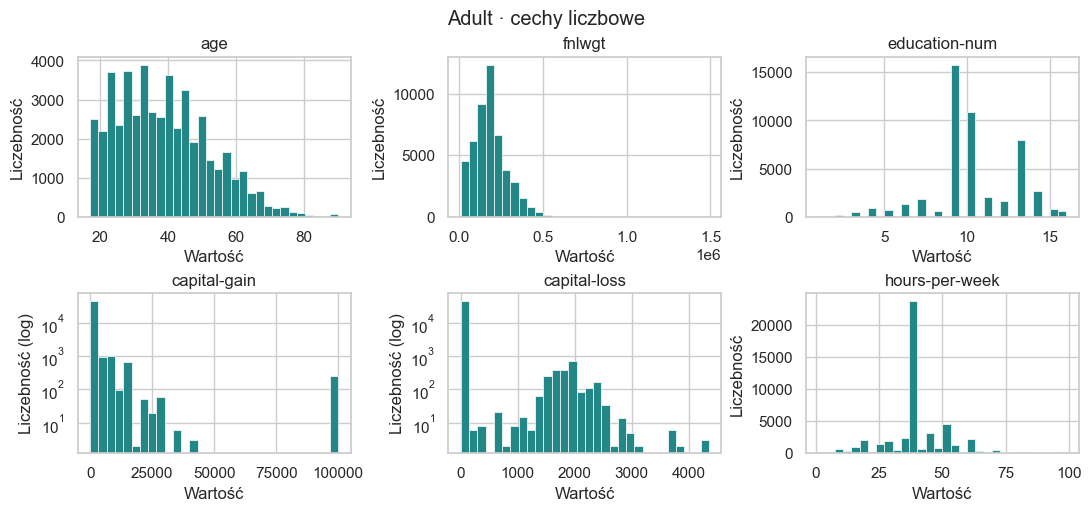

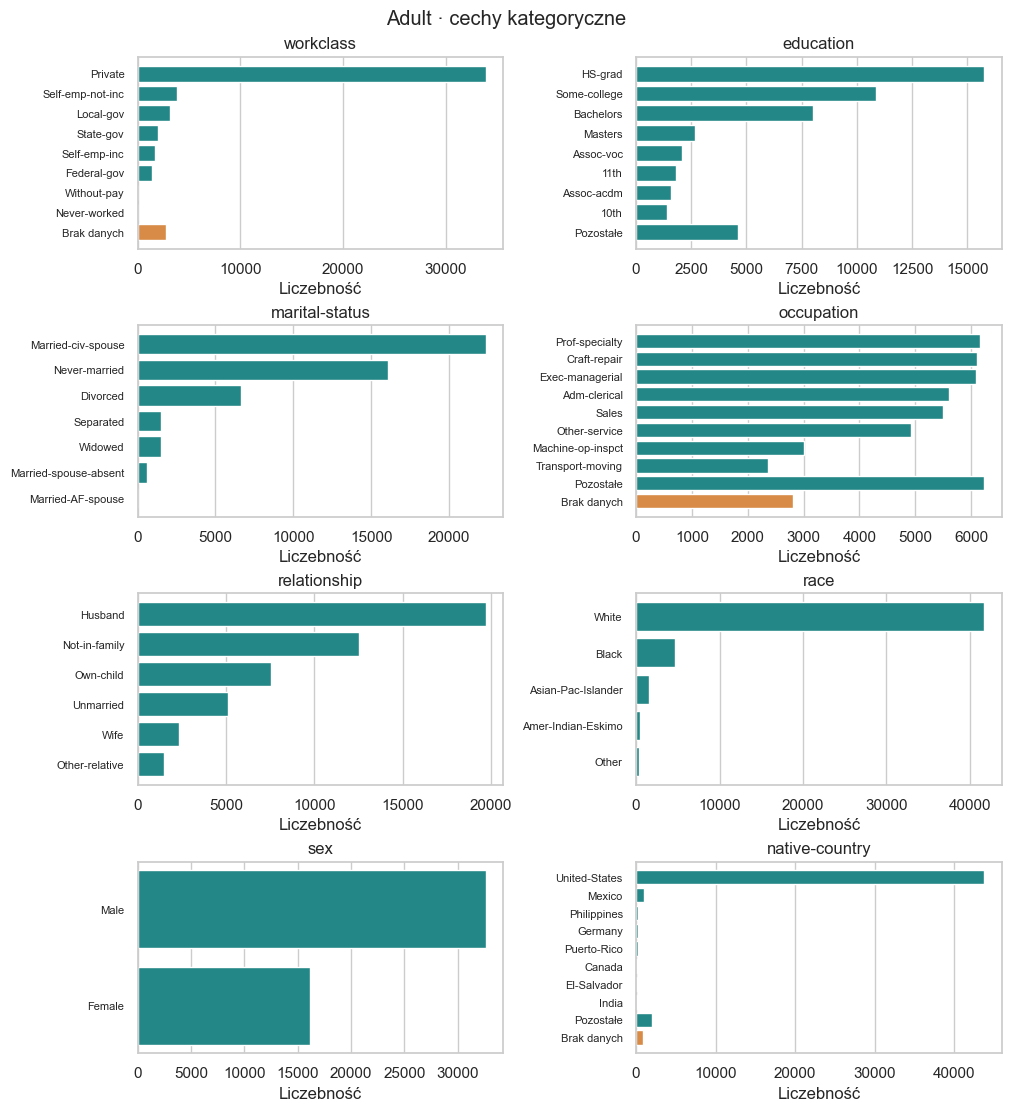

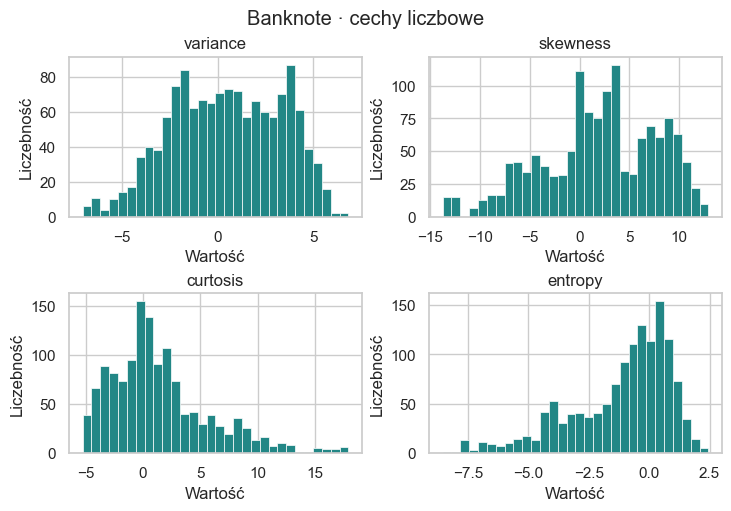

In [5]:
def plot_histograms(frame, columns, title, ncols):
    fig, axes = plt.subplots(2, ncols, figsize=(3.6 * ncols, 5), layout='constrained')
    for ax, column in zip(axes.flat, columns):
        use_log_counts = column in ('capital-gain', 'capital-loss')
        ax.hist(frame[column].dropna(), bins=30, color='#228786',
                edgecolor='white', linewidth=.5, log=use_log_counts)
        ylabel = 'Liczebność (log)' if use_log_counts else 'Liczebność'
        ax.set(title=column, xlabel='Wartość', ylabel=ylabel)
    fig.suptitle(title)
    plt.show()


plot_histograms(adult_data, ADULT_NUMERIC, 'Adult · cechy liczbowe', ncols=3)

categorical = [column for column in ADULT_COLUMNS if column not in ADULT_NUMERIC]
fig, axes = plt.subplots(4, 2, figsize=(10, 11), layout='constrained')
for ax, column in zip(axes.flat, categorical):
    counts = adult_data[column].value_counts()
    if len(counts) > 10:
        counts = pd.concat([counts.iloc[:8], pd.Series({'Pozostałe': counts.iloc[8:].sum()})])
    missing = adult_data[column].isna().sum()
    if missing:
        counts.loc['Brak danych'] = missing
    colors = ['#d78b46' if category == 'Brak danych' else '#228786' for category in counts.index]
    ax.barh(counts.index, counts.to_numpy(), color=colors)
    ax.invert_yaxis()
    ax.set(title=column, xlabel='Liczebność')
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(axis='y', visible=False)
fig.suptitle('Adult · cechy kategoryczne')
plt.show()


plot_histograms(bank_data, BANK_NUMERIC, 'Banknote · cechy liczbowe', ncols=2)


## Metoda

Dla każdego zbioru stosujemy jeden stratyfikowany podział 70/15/15 na trening, walidację i test. W Adult walidację i test ograniczamy do wspólnych kompletnych rekordów. W Banknote wykorzystujemy całą walidację i test. Imputację, skalowanie cech liczbowych i kodowanie one-hot kategorii dopasowujemy wyłącznie na treningu.

| Warianty | Obsługa braków | Skalowanie |
|---|---|---|
| A1, A2 | Mediana dla liczb, najczęstsza wartość dla kategorii | A1 standaryzacja, A2 Min–Max |
| B1, B2 | Usunięcie niekompletnych rekordów treningowych | B1 standaryzacja, B2 Min–Max |
| C1, C2 | Kategoria BRAK_DANYCH dla kategorii. Mediana i wskaźnik braku dla liczb z brakami. | C1 standaryzacja, C2 Min–Max |
| N1, N2 | Dane Banknote są kompletne | N1 standaryzacja, N2 Min–Max |
| A1-L1, N1-L1 · tylko SOM | Jak w A1 i N1 | Standaryzacja |
| A1-64x32 · tylko FFNN | Jak w A1 | Standaryzacja |
| A1-Leaky · tylko FFNN | Jak w A1 | Standaryzacja |

Omawiamy trzy porównania. **A1 i A2** pokazują wpływ skalowania w Adult, **A1 i B1** wpływ obsługi braków w Adult, a **N1 i N2** wpływ skalowania w Banknote. W każdej parze zmieniamy jeden element.

**FFNN** ma dwie warstwy ReLU (32 i 16 neuronów), wyjście sigmoid i optymalizator Adam. Trening trwa do 100 epok z wczesnym zatrzymaniem według straty walidacyjnej. W A1-64x32 podwajamy szerokość obu warstw, zachowując dwie warstwy i przygotowanie danych z A1. Szerokość wariantu ustalamy przed oceną testową. Przy strojeniu szerokości porównuje się ustalone wcześniej rozmiary na walidacji i wybiera najmniejszy model z porównywalnym wynikiem.

W A1-Leaky obie warstwy ukryte zachowują rozmiary 32 i 16 neuronów i używają LeakyReLU. Dla wartości ujemnych funkcja ma nachylenie 0,01. Na wyjściu pozostaje sigmoid, a dane i ustawienia treningu są takie jak w A1.

**SOM** używa siatki kwadratowej z rozmiarem ustalonym raz na zbiór i 10 000 aktualizacji. Wybór najlepiej dopasowanego neuronu opiera się domyślnie na odległości euklidesowej (L2). W A1-L1 i N1-L1 używamy odległości Manhattan (L1) przy tym samym preprocessingu i ustawieniach mapy co w A1 i N1. Ta sama metryka wybiera neurony podczas uczenia, przypisywania klas z rekordów treningowych i oceny testowej. Pusty neuron przejmuje klasę najbliższego oznaczonego neuronu według L2. Błąd topograficzny to odsetek próbek, dla których dwa najbliższe neurony nie sąsiadują na mapie.

Skalery i strategie braków porównujemy przy tych samych ustawieniach modeli i jednym ziarnie **42** dla podziału oraz treningu.

In [6]:
def build_preprocessor(x_train, numeric, strategy, scaler):
    categorical = [name for name in x_train.columns if name not in numeric]
    numeric_steps = []
    if strategy in ('A', 'C'):
        numeric_steps.append(('imputer', SimpleImputer(strategy='median')))
    numeric_steps.append(('scaler', SCALERS[scaler]()))
    branches = [('numeric', Pipeline(numeric_steps), numeric)]

    if categorical:
        category_steps = []
        if strategy == 'A':
            category_steps.append(('imputer', SimpleImputer(strategy='most_frequent')))
        if strategy == 'C':
            category_steps.append(('imputer', SimpleImputer(strategy='constant',
                                                              fill_value=MISSING_CATEGORY)))
        category_steps.append(('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)))
        branches.append(('categorical', Pipeline(category_steps), categorical))
    if strategy == 'C':
        missing_numeric = x_train[numeric].columns[x_train[numeric].isna().any()].tolist()
        if missing_numeric:
            branches.append(('missing', MissingIndicator(features='all'), missing_numeric))
    return ColumnTransformer(branches)


def prepare_variant(splits, y, numeric, strategy, scaler):
    x_train, x_val, x_test = splits
    if strategy == 'B':
        x_train = x_train.dropna()

    preprocessor = build_preprocessor(x_train, numeric, strategy, scaler).fit(x_train)
    feature_count = len(preprocessor.get_feature_names_out())

    def transform(part):
        values = np.asarray(preprocessor.transform(part), dtype=np.float32)
        if values.shape != (len(part), feature_count) or not np.isfinite(values).all():
            raise ValueError('Nieprawidłowy kształt lub braki po preprocessingu.')
        return values, y.loc[part.index].to_numpy()

    return transform(x_train), transform(x_val), transform(x_test)

In [7]:
def fit_ffnn(train, val, seed, *, hidden_units=None, negative_slope=None):
    x_train, _ = train
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    if hidden_units is None:
        hidden_units = FFNN['hidden_units']
    hidden_layers = []
    for units in hidden_units:
        activation = FFNN['hidden_activation']
        if negative_slope is not None:
            activation = keras.layers.LeakyReLU(negative_slope=negative_slope)
        hidden_layers.append(keras.layers.Dense(units, activation=activation))
    model = keras.Sequential([
        keras.Input(shape=(x_train.shape[1],)),
        *hidden_layers,
        keras.layers.Dense(1, activation=FFNN['output_activation']),
    ])
    model.compile(
        optimizer=FFNN['optimizer'](learning_rate=FFNN['learning_rate']),
        loss=FFNN['loss'], steps_per_execution=16,
    )
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    training = tf.data.Dataset.from_tensor_slices(train)
    training = training.shuffle(len(x_train), seed=seed).batch(FFNN['batch_size'])
    validation = tf.data.Dataset.from_tensor_slices(val).batch(FFNN['batch_size'])
    early_stop = keras.callbacks.EarlyStopping(
        monitor=FFNN['monitor'], patience=FFNN['patience'], restore_best_weights=True,
    )
    model.fit(
        training.with_options(options), validation_data=validation.with_options(options),
        epochs=FFNN['max_epochs'], callbacks=[early_stop], shuffle=False, verbose=0,
    )
    return model


def closest_neurons(samples, weights, activation_distance, *, find_two=False):
    metric = CDIST_METRICS[activation_distance]
    winners, runners_up = [], []
    size = SOM['distance_batch_size']
    for start in range(0, len(samples), size):
        distances = cdist(samples[start:start + size], weights, metric=metric)
        best = distances.argmin(axis=1)
        winners.append(best)
        if find_two:
            distances[np.arange(len(best)), best] = np.inf
            runners_up.append(distances.argmin(axis=1))
    return np.concatenate(winners), np.concatenate(runners_up) if find_two else None


def fit_som(x_train, side, seed, activation_distance):
    som = MiniSom(
        side, side, x_train.shape[1], random_seed=seed,
        sigma=max(SOM['sigma_min'], side / SOM['sigma_divisor']),
        learning_rate=SOM['learning_rate'], topology=SOM['topology'],
        activation_distance=activation_distance,
        neighborhood_function=SOM['neighborhood_function'],
        decay_function=SOM['decay_function'], sigma_decay_function=SOM['sigma_decay_function'],
    )
    som.random_weights_init(x_train)
    rng = np.random.default_rng(seed)
    for step, index in enumerate(rng.integers(len(x_train), size=SOM['updates'])):
        sample = x_train[index]
        som.update(sample, som.winner(sample), step, SOM['updates'])
    return som


def label_som(x_train, y_train, weights, activation_distance):
    winners, _ = closest_neurons(x_train, weights, activation_distance)
    votes = np.zeros((len(weights), 2), dtype=int)
    np.add.at(votes, (winners, y_train), 1)
    overall_majority = np.bincount(y_train, minlength=2).argmax()
    labels = np.where(votes[:, 0] == votes[:, 1], overall_majority, votes.argmax(axis=1))
    occupied = votes.sum(axis=1) > 0
    assigned = np.flatnonzero(occupied)
    nearest_assigned = cdist(weights[~occupied], weights[assigned], metric='euclidean').argmin(axis=1)
    labels[~occupied] = labels[assigned[nearest_assigned]]
    return labels


def evaluate_som(x, weights, labels, side, activation_distance):
    winner, runner_up = closest_neurons(x, weights, activation_distance, find_two=True)
    row_gap = winner // side - runner_up // side
    col_gap = winner % side - runner_up % side
    nonadjacent = row_gap**2 + col_gap**2 > 2
    norm_order = 1 if activation_distance == 'manhattan' else 2
    qe = np.linalg.norm(x - weights[winner], ord=norm_order, axis=1).mean()
    return labels[winner], qe, nonadjacent.mean()

## Wyniki

Podajemy wyniki pojedynczego treningu każdego modelu w każdym wariancie. Macro-recall i macro-F1 to średnie wartości odpowiednich metryk dla obu klas. F1 klasy >50K pokazuje skuteczność rozpoznawania wyższych dochodów w Adult. Metryki klasyfikacji i błąd topograficzny (TE) są w skali od 0 do 1.

W macierzach pomyłek wiersze oznaczają klasy rzeczywiste, a kolumny klasy przewidziane. Na przekątnej są poprawne predykcje. Liczby oznaczają rekordy testowe.

Błąd kwantyzacji (QE) to średnia odległość rekordu testowego od jego najlepiej dopasowanego neuronu. Do obliczenia QE stosujemy tę samą metrykę co przy dopasowaniu neuronu (L1 albo L2). Bezpośrednie porównanie QE ma sens przy tej samej metryce i reprezentacji danych.

Na mapie klas kolor oznacza etykietę przypisaną neuronowi na podstawie danych treningowych. Neurony bez trafień przejmują etykietę najbliższego oznaczonego neuronu. Jasne obszary U-matrix wskazują duże względne różnice między sąsiadującymi neuronami. U-matrix we wszystkich wariantach używa odległości euklidesowej między wagami neuronów.

In [8]:
def classification_scores(y, predicted):
    report = classification_report(
        y, predicted, labels=[0, 1], output_dict=True, zero_division=0,
    )
    return {
        'Accuracy': report['accuracy'],
        'Macro-recall': report['macro avg']['recall'],
        'Macro-F1': report['macro avg']['f1-score'],
        'F1 klasy >50K': report['1']['f1-score'],
    }


def run_experiment(splits, y, numeric, variants, *, complete_evaluation=False):
    x_train, x_val, x_test = splits
    if complete_evaluation:
        x_val, x_test = x_val.dropna(), x_test.dropna()
    side = round(np.sqrt(SOM['neurons_factor'] * np.sqrt(len(x_train))))
    records, maps, matrices = [], {}, {}
    for variant, (strategy, scaler) in variants.items():
        train, val, test = prepare_variant((x_train, x_val, x_test), y, numeric, strategy, scaler)
        train_x, train_y = train
        test_x, test_y = test
        common = {'Wariant': variant, 'Trening': len(train_y), 'Test': len(test_y)}
        if variant not in SOM_ONLY_VARIANTS:
            model = fit_ffnn(train, val, SEED, **FFNN_ONLY_VARIANTS.get(variant, {}))
            probability = model(test_x, training=False).numpy().ravel()
            predicted = (probability >= FFNN['threshold']).astype(int)
            matrices[(variant, 'FFNN')] = confusion_matrix(test_y, predicted, labels=[0, 1])
            records.append({**common, 'Model': 'FFNN', **classification_scores(test_y, predicted)})

        if variant in FFNN_ONLY_VARIANTS:
            continue

        activation_distance = SOM_ONLY_VARIANTS.get(variant, SOM['activation_distance'])
        som = fit_som(train_x, side, SEED, activation_distance)
        weights = som.get_weights().reshape(side * side, -1)
        labels = label_som(train_x, train_y, weights, activation_distance)
        predicted, qe, te = evaluate_som(test_x, weights, labels, side, activation_distance)
        matrices[(variant, 'SOM')] = confusion_matrix(test_y, predicted, labels=[0, 1])
        records.append({**common, 'Model': 'SOM', **classification_scores(test_y, predicted),
                        'Błąd kwantyzacji (QE)': qe, 'Błąd topograficzny': te})
        maps[variant] = {
            'U-matrix': som.distance_map(scaling='mean'),
            'Klasy neuronów': labels.reshape(side, side),
        }
    return pd.DataFrame(records).set_index(['Wariant', 'Model']), maps, matrices


def plot_confusion_matrices(matrices, labels, dataset):
    ncols = 4
    nrows = (len(matrices) + ncols - 1) // ncols
    vmax = max(matrix.max() for matrix in matrices.values())
    fig, axes = plt.subplots(nrows, ncols, figsize=(10, 2.35 * nrows),
                             squeeze=False, layout='constrained')
    for index, ((variant, model), matrix) in enumerate(matrices.items()):
        row, col = divmod(index, ncols)
        ax = axes[row, col]
        ConfusionMatrixDisplay(matrix, display_labels=labels).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d',
            im_kw={'vmin': 0, 'vmax': vmax},
        )
        ax.grid(False)
        ax.set(title=f'{variant} · {model}',
               xlabel='Przewidziana' if row == nrows - 1 else '',
               ylabel='Rzeczywista' if col == 0 else '')
    for ax in list(axes.flat)[len(matrices):]:
        ax.set_visible(False)
    fig.suptitle(f'{dataset} · macierze pomyłek')
    plt.show()


def plot_macro_f1(results, dataset):
    fig, ax = plt.subplots(figsize=(7.5, 3.2), layout='constrained')
    sns.barplot(data=results.reset_index(), x='Wariant', y='Macro-F1',
                hue='Model', palette=['#228786', '#d78b46'], errorbar=None, ax=ax)
    for bars in ax.containers:
        ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=9)
    ax.set(ylim=(0, 1.1), yticks=np.linspace(0, 1, 6),
           title=f'{dataset} · Macro-F1 na teście')
    ax.legend(title=None, loc='lower right')
    plt.show()


def plot_som_maps(maps, variants, dataset, class_labels):
    nrows = (len(maps) + 1) // 2
    class_colors = ListedColormap(['#366ca0', '#e39a4c'])
    styles = {
        'U-matrix': dict(cmap='viridis', vmin=0, vmax=1),
        'Klasy neuronów': dict(cmap=class_colors, vmin=-.5, vmax=1.5),
    }
    for kind, style in styles.items():
        fig, axes = plt.subplots(nrows, 2, figsize=(6.4, 3 * nrows),
                                 squeeze=False, layout='constrained')
        for ax, (variant, panels) in zip(axes.flat, maps.items()):
            heat = ax.imshow(panels[kind], interpolation='nearest', **style)
            ax.set(title=f'{variant} · {variants[variant][1]}', xticks=[], yticks=[])
        for ax in list(axes.flat)[len(maps):]:
            ax.set_visible(False)
        colorbar = fig.colorbar(heat, ax=axes, shrink=.8)
        if kind == 'Klasy neuronów':
            colorbar.set_ticks([0, 1], labels=class_labels)
        else:
            colorbar.set_label('Względna odległość L2')
        fig.suptitle(f'{dataset} · SOM · {kind}')
        plt.show()

### Adult

Trening  Test  Accuracy  Macro-recall  Macro-F1  \
Wariant  Model                                                    
A1       FFNN     34153  6749    0.8548        0.7742    0.7919   
         SOM      34153  6749    0.8218        0.7106    0.7321   
A2       FFNN     34153  6749    0.8524        0.7742    0.7900   
         SOM      34153  6749    0.8225        0.7123    0.7337   
B1       FFNN     31639  6749    0.8545        0.7935    0.8004   
         SOM      31639  6749    0.8231        0.7233    0.7413   
B2       FFNN     31639  6749    0.8509        0.7748    0.7892   
         SOM      31639  6749    0.8249        0.7181    0.7390   
C1       FFNN     34153  6749    0.8546        0.7795    0.7943   
         SOM      34153  6749    0.8235        0.7106    0.7331   
C2       FFNN     34153  6749    0.8529        0.7751    0.7908   
         SOM      34153  6749    0.8203        0.7146    0.7340   
A1-L1    SOM      34153  6749    0.8200        0.7047    0.7269   
A1-64x32 FFNN     34153  6749    0.8564        0.7870    0.7991   
A1-Leaky FFNN     34153  6749    0.8548        0.7742    0.7919   

                F1 klasy >50K Błąd kwantyzacji (QE) Błąd topograficzny  
Wariant  Model                                                          
A1       FFNN          0.6774                     —                  —  
         SOM           0.5772                2.0159             0.0262  
A2       FFNN          0.6756                     —                  —  
         SOM           0.5799                1.4135             0.0129  
B1       FFNN          0.6965                     —                  —  
         SOM           0.5958                 2.022             0.0163  
B2       FFNN          0.6751                     —                  —  
         SOM           0.5893                1.4049             0.0142  
C1       FFNN          0.6828                     —                  —  
         SOM           0.5778                2.0252             0.0236  
C2       FFNN          0.6769                     —                  —  
         SOM           0.5824                1.4187              0.011  
A1-L1    SOM           0.5675                7.7829             0.0658  
A1-64x32 FFNN          0.6919                     —                  —  
A1-Leaky FFNN          0.6774                     —                  —

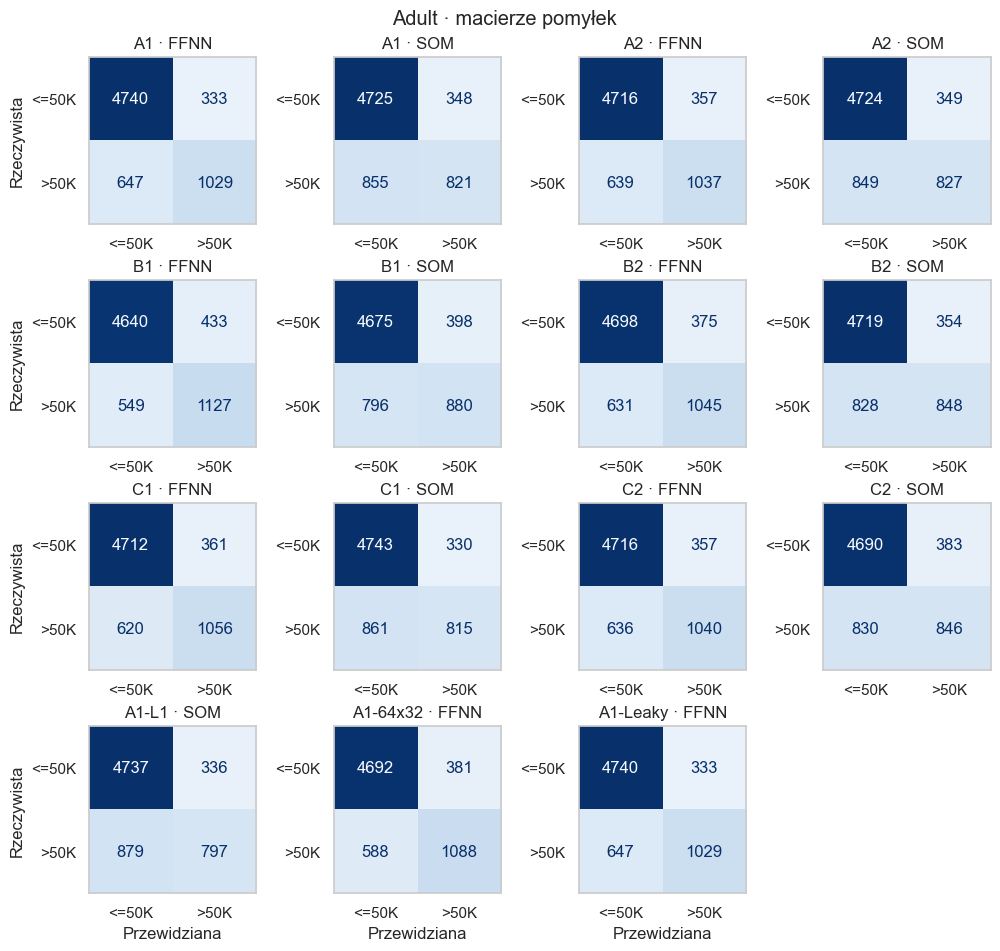

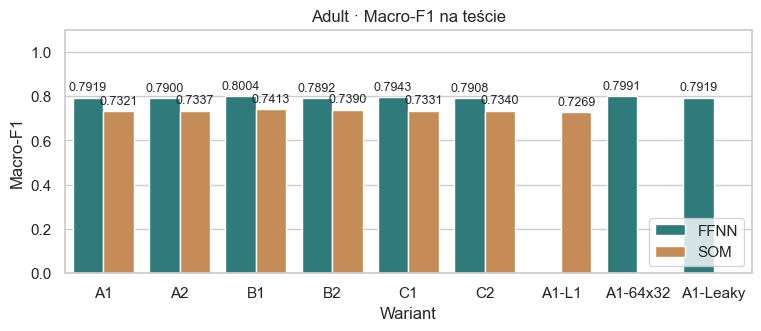

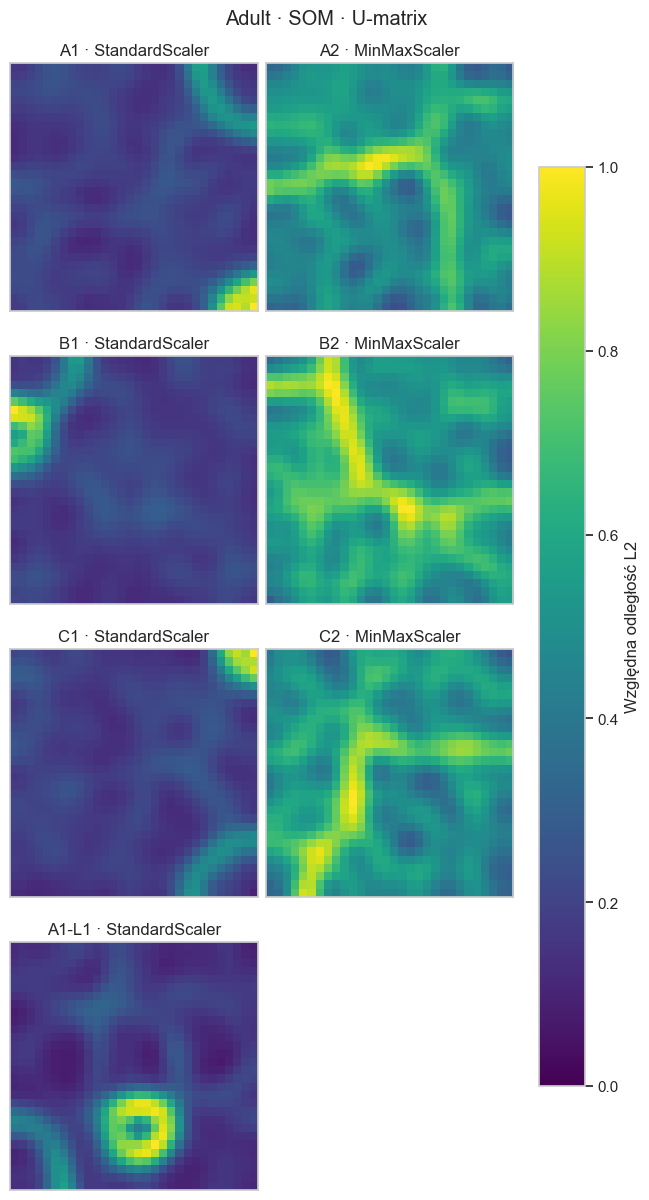

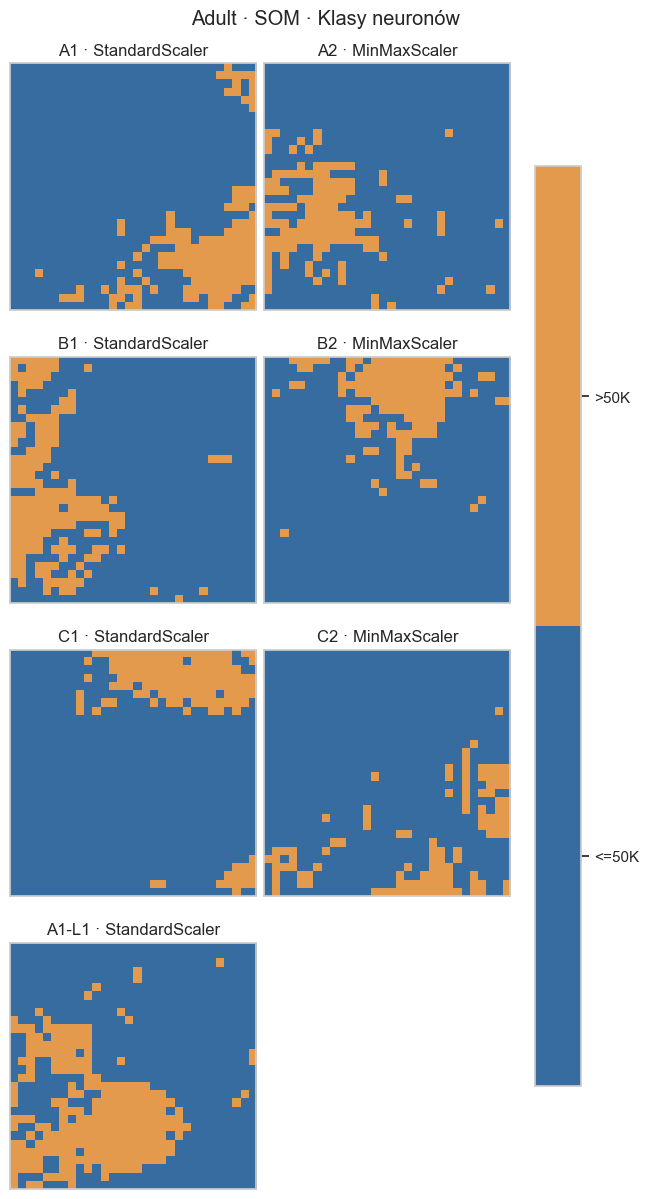

In [9]:
adult_results, adult_maps, adult_matrices = run_experiment(
    adult_splits, adult_y, ADULT_NUMERIC, ADULT_VARIANTS, complete_evaluation=True,
)
display(adult_results.round(4).replace({np.nan: '—'}))

plot_confusion_matrices(adult_matrices, ['<=50K', '>50K'], 'Adult')

plot_macro_f1(adult_results, 'Adult')
plot_som_maps(adult_maps, ADULT_VARIANTS, 'Adult', ['<=50K', '>50K'])

**Struktura map Adult.** W A1 neurony z etykietą >50K skupiają się głównie przy prawej i dolnej krawędzi. W A2 większe skupisko jest po lewej, z pojedynczymi neuronami tej klasy także w innych częściach mapy. Jasne pasmo po prawej w U-matrix A2 przebiega również przez obszar <=50K. W tym obszarze sąsiednie neurony mogą się wyraźnie różnić mimo wspólnej etykiety.

### Banknote

Trening  Test  Accuracy  Macro-recall  Macro-F1  \
Wariant Model                                                    
N1      FFNN       943   203    1.0000        1.0000    1.0000   
        SOM        943   203    0.9901        0.9910    0.9901   
N2      FFNN       943   203    1.0000        1.0000    1.0000   
        SOM        943   203    0.9951        0.9955    0.9950   
N1-L1   SOM        943   203    0.9901        0.9891    0.9900   

              Błąd kwantyzacji (QE) Błąd topograficzny  
Wariant Model                                           
N1      FFNN                      —                  —  
        SOM                  0.4174             0.0296  
N2      FFNN                      —                  —  
        SOM                  0.0829             0.0148  
N1-L1   SOM                  0.6784             0.0246

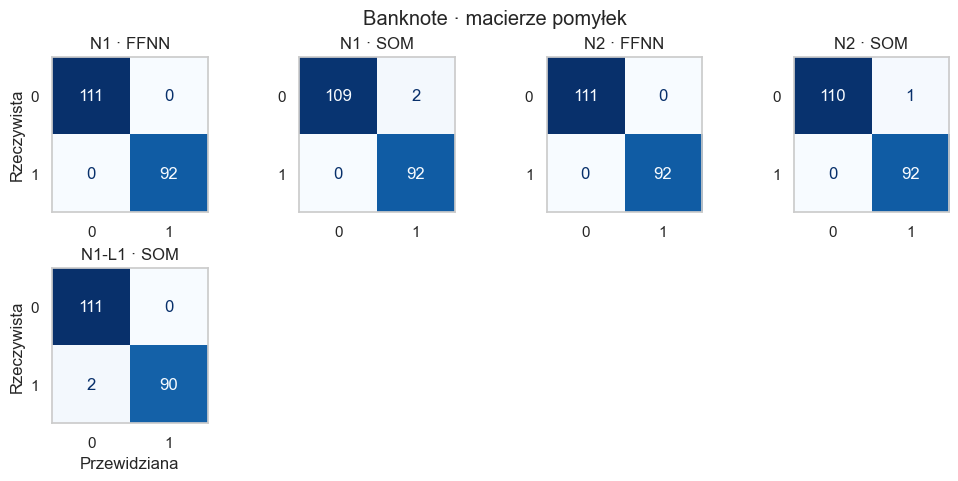

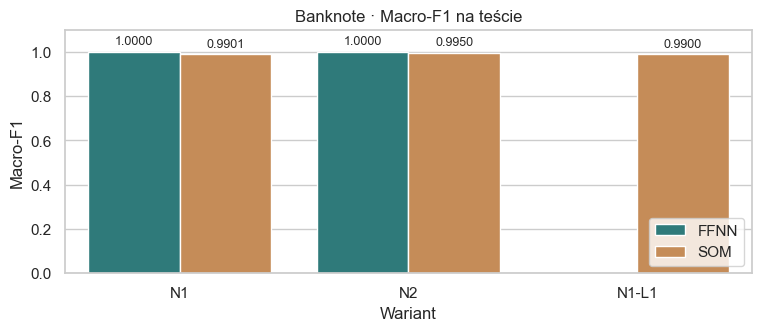

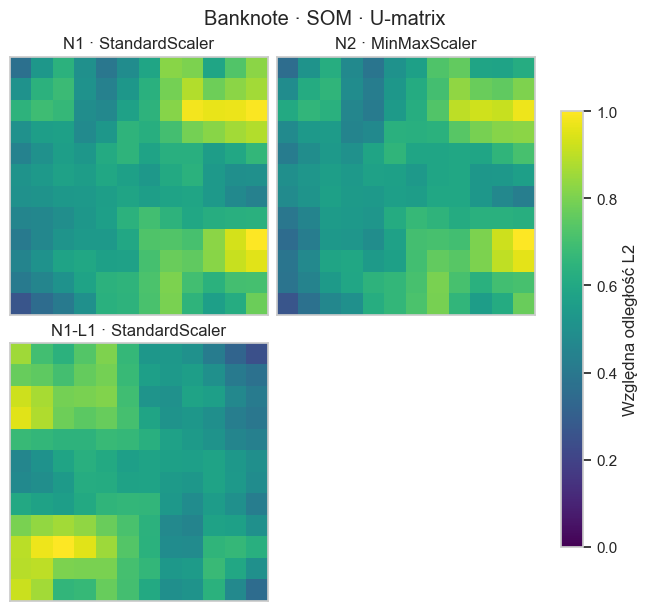

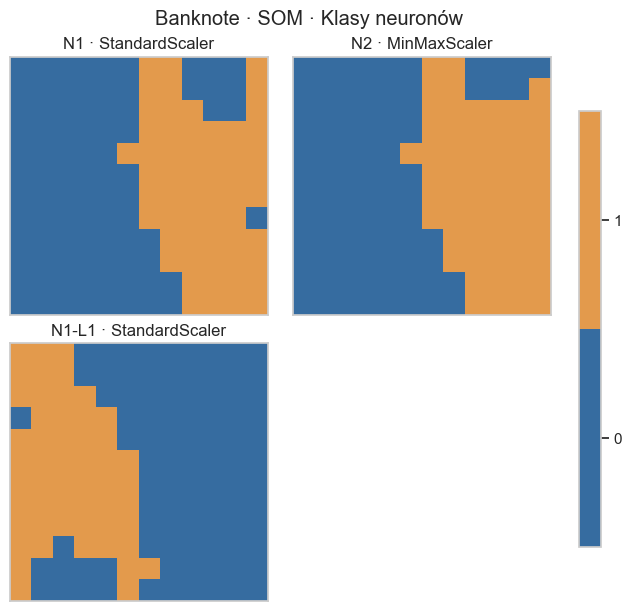

In [10]:
bank_results, bank_maps, bank_matrices = run_experiment(
    bank_splits, bank_y, BANK_NUMERIC, BANK_VARIANTS,
)
display(bank_results.drop(columns='F1 klasy >50K').round(4).replace({np.nan: '—'}))

plot_confusion_matrices(bank_matrices, ['0', '1'], 'Banknote')

plot_macro_f1(bank_results, 'Banknote')
plot_som_maps(bank_maps, BANK_VARIANTS, 'Banknote', ['0', '1'])

**Struktura map Banknote.** W obu wariantach klasa 0 zajmuje głównie lewą część mapy, a klasa 1 prawą. Pojedynczemu polu klasy 0 przy prawej krawędzi N1 odpowiada w N2 pole klasy 1. Największe lokalne różnice między neuronami w U-matrix widać po prawej stronie obu map, również wewnątrz obszaru klasy 1. Na teście błąd topograficzny wyniósł 2,96% dla N1 i 1,48% dla N2.

## Wnioski i ograniczenia

In [11]:
def change_pp(results, start, end, metric, model):
    return 100 * (results.loc[(end, model), metric] - results.loc[(start, model), metric])


def macro_change(results, start, end):
    return ', '.join(f"{model} {change_pp(results, start, end, 'Macro-F1', model):+.2f} p.p."
                     for model in ('FFNN', 'SOM'))


adult_train = adult_splits[0]
removed = 100 * adult_train.isna().any(axis=1).mean()
adult_f1 = change_pp(adult_results, 'A1', 'A2', 'F1 klasy >50K', 'FFNN')
bank_te = change_pp(bank_results, 'N1', 'N2', 'Błąd topograficzny', 'SOM')
display(Markdown(
    f"- **Skalowanie w Adult (A1 → A2).** Zmiana macro-F1 po przejściu na Min–Max to "
    f"({macro_change(adult_results, 'A1', 'A2')}). F1 klasy >50K dla FFNN zmieniło się o {adult_f1:+.2f} p.p.\n"
    f"- **Braki w Adult (A1 → B1).** Usunięto {removed:.2f}% wierszy treningowych. Przy tym samym skalerze "
    f"zmiana macro-F1 to ({macro_change(adult_results, 'A1', 'B1')}).\n"
    f"- **Skalowanie w Banknote (N1 → N2).** Zmiana macro-F1 po przejściu na Min–Max to "
    f"({macro_change(bank_results, 'N1', 'N2')}). Błąd topograficzny SOM zmienił się o {bank_te:+.2f} p.p."
))

for dataset, results, baseline in (
    ('Adult', adult_results, 'A1'), ('Banknote', bank_results, 'N1'),
):
    l1 = f'{baseline}-L1'
    macro_l2 = results.loc[(baseline, 'SOM'), 'Macro-F1']
    macro_l1 = results.loc[(l1, 'SOM'), 'Macro-F1']
    te_delta = change_pp(results, baseline, l1, 'Błąd topograficzny', 'SOM')
    display(Markdown(
        f'**Odległość L1 w SOM · {dataset} ({baseline} → {l1}).** '
        f'Macro-F1 {macro_l2:.4f} → {macro_l1:.4f}. Zmiana TE {te_delta:+.2f} p.p.'
    ))

baseline_ffnn = adult_results.loc[('A1', 'FFNN')]
wider_ffnn = adult_results.loc[('A1-64x32', 'FFNN')]
display(Markdown(
    '**Szerokość FFNN w Adult (A1 → A1-64x32).** '
    f"Macro-F1 {baseline_ffnn['Macro-F1']:.4f} → {wider_ffnn['Macro-F1']:.4f}. "
    f"F1 klasy >50K {baseline_ffnn['F1 klasy >50K']:.4f} → {wider_ffnn['F1 klasy >50K']:.4f}."
))

leaky_ffnn = adult_results.loc[('A1-Leaky', 'FFNN')]
display(Markdown(
    '**Aktywacja FFNN w Adult (A1 → A1-Leaky).** '
    f"Macro-F1 {baseline_ffnn['Macro-F1']:.4f} → {leaky_ffnn['Macro-F1']:.4f}. "
    f"F1 klasy >50K {baseline_ffnn['F1 klasy >50K']:.4f} → {leaky_ffnn['F1 klasy >50K']:.4f}."
))

- **Skalowanie w Adult (A1 → A2).** Zmiana macro-F1 po przejściu na Min–Max to (FFNN -0.18 p.p., SOM +0.16 p.p.). F1 klasy >50K dla FFNN zmieniło się o -0.18 p.p.
- **Braki w Adult (A1 → B1).** Usunięto 7.36% wierszy treningowych. Przy tym samym skalerze zmiana macro-F1 to (FFNN +0.86 p.p., SOM +0.92 p.p.).
- **Skalowanie w Banknote (N1 → N2).** Zmiana macro-F1 po przejściu na Min–Max to (FFNN +0.00 p.p., SOM +0.50 p.p.). Błąd topograficzny SOM zmienił się o -1.48 p.p.

**Odległość L1 w SOM · Adult (A1 → A1-L1).** Macro-F1 0.7321 → 0.7269. Zmiana TE +3.96 p.p.

**Odległość L1 w SOM · Banknote (N1 → N1-L1).** Macro-F1 0.9901 → 0.9900. Zmiana TE -0.49 p.p.

**Szerokość FFNN w Adult (A1 → A1-64x32).** Macro-F1 0.7919 → 0.7991. F1 klasy >50K 0.6774 → 0.6919.

**Aktywacja FFNN w Adult (A1 → A1-Leaky).** Macro-F1 0.7919 → 0.7919. F1 klasy >50K 0.6774 → 0.6774.

Wyniki pokazują, jak oba modele reagują na przetwarzanie danych. Różnice między FFNN i SOM odczytujemy w obrębie tego samego wariantu. Wnioski dotyczą jednego podziału, jednego ziarna i ustalonych parametrów sieci. W Adult odnoszą się do kompletnych rekordów testowych.